# Forecasting & Prediction: the linear regression model

## Introduction

How much will a leased laptop be worth when the client returns it? The lecture introduced this forecasting problem. Let's now use Python to explore the data, fit a regression model and put its predictions to the test.

The worked examples show how tables, plots and two modeling libraries fit together in a forecasting workflow. As you follow the code, consider what the outputs tell us about resale prices. The tasks at the end give you a chance to develop your own code.

Here's our route through the notebook:

1. [Case study: forecasting residual values in the leasing business](#leasing): explore the resale-price data with pandas and seaborn.
2. [The linear regression model](#linear-regression): fit a model, interpret its coefficients and predict prices with scikit-learn and statsmodels.
3. [Measuring forecast accuracy](#forecast-accuracy): compare against a simple benchmark, use cross-validation and calculate percentage errors.
4. [Summary](#summary): revisit the main concepts and Python tools.
5. [Tasks](#tasks): put your coding skills into practice.

### Meet the libraries

Much of Python's appeal for data science comes from its libraries. We'll use a few that you will meet throughout the course:

| Library | What you will use it for |
|---|---|
| NumPy (`np`) | Calculate with arrays and check numerical results |
| pandas (`pd`) | Load, inspect and summarize tables |
| Matplotlib (`plt`) | Arrange plots and label axes |
| seaborn (`sns`) | Create statistical graphics with little code |
| scikit-learn | Fit models, make predictions and evaluate them |
| statsmodels | Write regression formulas and inspect fitted coefficients |

Let's import these tools. The short names `np`, `pd`, `plt` and `sns` are common conventions, so you will recognize them in many other examples. Jupyter's `display` function helps us show several tables in one cell.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split, KFold, cross_validate

# Reuse this seed to reproduce the data split and cross-validation folds.
SEED = 67

# Give our plots a consistent appearance.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)

<a id="leasing"></a>
## 1. Case study: forecasting residual values in the leasing business

*Recall slides 7–10.*

A lessor buys equipment, leases it to a client and later resells it. To set a lease payment, the lessor needs an estimate of the equipment's resale value. Historical cases help us learn the relationship between an item's characteristics and its resale price.

This is a **regression** problem: we predict a numerical **target** from a set of **features**. Here, we'll predict the resale price at the start of a lease using retail price, agreed lease duration and RAM capacity. At that point, we don't yet know the actual return date or the battery condition on return.

### 1.1 Load the data with pandas

`pd.read_csv` reads a CSV file into a `DataFrame`: a table with rows and columns. We can even pass a web address directly. Let's load the course dataset and give a few columns shorter names so our code is easier to read.

In [2]:
# Read the resale price forecasting dataset from our data folder
url = "../data/resale_price_dataset.csv"
raw = pd.read_csv(url)

# Keep the columns we need and give them shorter names.
column_names = {
    "Retail price": "list_price",
    "Contract Lease Duration (months)": "lease_months",
    "RAM size (GB)": "ram_gb",
    "Industry": "industry",
    "Observed resale price": "resale_price",
}
data = raw[list(column_names)].rename(columns=column_names)

print(f"We have {len(data):,} cases.")
display(data.head())  # Show the first five rows.

We have 5,000 cases.


,list_price,lease_months,ram_gb,industry,resale_price
0,2699,60,16,Automotive and Transportation,751
1,2719,6,16,Healthcare,2599
2,2759,24,16,Automotive and Transportation,1358
3,2639,36,16,Automotive and Transportation,1166
4,2659,12,16,Agriculture and Farming,1915


### 1.2 Get to know the data

Before fitting a model, take a look at the columns. What types of values do they contain? Are any entries missing? What ranges do you see?

`info()` gives you an overview of column types and non-missing values. `describe()` summarizes the numerical columns. Duration is in months, RAM is in GB and prices use the monetary units in the course data.

In [3]:
# Inspect column types and the number of non-missing entries.
data.info()

# Summarize the numerical columns.
display(data.describe().round(2))

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   list_price    5000 non-null   int64
 1   lease_months  5000 non-null   int64
 2   ram_gb        5000 non-null   int64
 3   industry      5000 non-null   str  
 4   resale_price  5000 non-null   int64
dtypes: int64(4), str(1)
memory usage: 195.4 KB


,list_price,lease_months,ram_gb,resale_price
count,5000.00,5000.00,5000.0,5000.00
mean,2252.57,28.07,9.4,1199.53
std,991.66,16.04,5.0,649.13
min,649.00,6.00,4.0,0.00
25%,1509.00,12.00,4.0,725.00
50%,2019.00,24.00,8.0,1069.00
75%,2919.00,36.00,16.0,1529.00
max,5719.00,60.00,16.0,4550.00


`groupby` brings related rows together for group-level summaries. The example below groups cases by client industry and calculates a few statistics with `agg`.

Which industries appear most often? Compare their typical equipment prices as well as their resale prices. A difference in resale prices alone doesn't tell us whether the industries use comparable equipment.

In [4]:
# Summarize each industry and show the eight largest groups.
industry_summary = (
    data.groupby("industry")
    .agg(
        cases=("resale_price", "size"),
        median_list_price=("list_price", "median"),
        median_resale_price=("resale_price", "median"),
    )
    .sort_values("cases", ascending=False)
)
display(industry_summary.head(8).round(2))

,cases,median_list_price,median_resale_price
industry,,,
Advertising and Marketing,242,2069.0,1039.5
Media and Entertainment,239,2079.0,1050.0
Information Technology,230,2054.0,985.5
Consulting,230,1944.0,1104.0
Travel and Hospitality,227,2049.0,1082.0
Telecommunications,220,1964.0,1060.5
Education,220,1979.0,1009.0
Energy and Utilities,219,2029.0,1102.0


### 1.3 Take a graphical look

Let's move from tables to plots. A histogram shows how resale prices are distributed; a scatter plot shows how prices vary with agreed lease duration.

Seaborn lets us refer to columns by name. With Matplotlib's `subplots`, we can place two plots side by side and label their axes. Look at the scatter plot: how much variation remains among leases of the same duration?

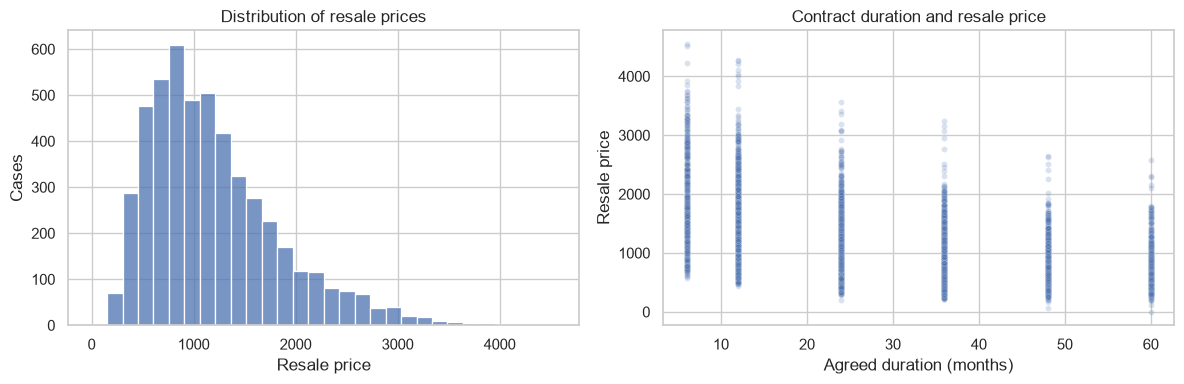

In [ ]:
# Create two panels: one for a distribution, one for a relationship.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=data, x="resale_price", bins=30, ax=axes[0])
axes[0].set(title="Distribution of resale prices", xlabel="Resale price", ylabel="Cases")
sns.scatterplot(
    data=data, x="lease_months", y="resale_price",
    alpha=0.2, s=18, ax=axes[1],
)
axes[1].set(title="Contract duration and resale price", xlabel="Agreed duration (months)",
            ylabel="Resale price")
fig.tight_layout()
plt.show()

#we have a large resale price that are on the right part of the graph

<a id="linear-regression"></a>
## 2. The linear regression model

*Recall slides 11–20.*

The lecture introduced linear regression as an additive model. With our three features, we predict resale price as

$$\widehat{y} = b + w_1\,\text{list price} + w_2\,\text{lease months} + w_3\,\text{RAM GB}.$$

Training means estimating the intercept and coefficients from labeled cases. Let's ask Python to do that using ordinary least squares.

### 2.1 Separate features, target and test cases

First, we need to organize the data. Remember this diagram from the lecture?

![Holdout method: fit a model on training cases, then compare its predictions with observed targets on separate test cases.](../resources/holdout_method.png)

We'll keep 25% of the cases for testing and fit our model on the remaining 75%. For this example, we treat cases as independent observations from the same population.

scikit-learn expects **X** to be a two-dimensional feature table and **y** to be a one-dimensional target. Selecting a list of column names gives us a DataFrame; selecting one column name gives us a Series.

In [7]:
# Separate the input features from the target we want to predict.
FEATURES = ["list_price", "lease_months", "ram_gb"]
TARGET = "resale_price"
X = data[FEATURES]
y = data[TARGET]

# Split features and target together so the rows stay aligned.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED,
)
print("Training shapes:", X_train.shape, y_train.shape)
print("Test shapes:", X_test.shape, y_test.shape)

Training shapes: (3750, 3) (3750,)
Test shapes: (1250, 3) (1250,)


### 2.2 Fit your first scikit-learn regression

You'll see the same pattern throughout scikit-learn: **create a model → fit it → make predictions**.

`fit(X, y)` learns the parameters from the training cases. After fitting, `intercept_` and `coef_` give us the estimated intercept and coefficients. The trailing underscore signals an attribute that the model learned during fitting.

In [8]:
# Create a linear regression model and estimate its parameters.
regression = LinearRegression()
regression.fit(X_train, y_train)

# Match each coefficient to its feature name.
print(f"Intercept: {regression.intercept_:.2f}")
coefficients = pd.Series(regression.coef_, index=FEATURES, name="Coefficient")
display(coefficients.round(3))

Intercept: 625.11


list_price       0.512
lease_months   -19.945
ram_gb          -2.083
Name: Coefficient, dtype: float64

A coefficient describes a predicted change **holding the other included features constant**. The duration coefficient, for example, describes the predicted price difference for one extra agreed month at the same list price and RAM capacity. What sign did you expect? Does the fitted value agree?

Remember that coefficients depend on units. Each coefficient describes an association on its feature’s measurement scale. Causal effects require a separate identification strategy. The intercept describes a case with all three features equal to zero, outside our observed range.

### 2.3 Make a prediction

Suppose we want to price a new lease. The next cell puts its features in a DataFrame and calls `predict`, using the same feature names and order as in training.

We can also evaluate the fitted equation ourselves. NumPy's `@` operator multiplies the feature values by their coefficients and adds the products. Do the two routes give the same result?

In [ ]:
# Describe one new lease using the same columns as the training data.
new_lease = pd.DataFrame({
    "list_price": [2200.0],
    "lease_months": [24.0],
    "ram_gb": [8.0],
})

# Ask the fitted model for a forecast.
library_prediction = regression.predict(new_lease)
print("Prediction from scikit-learn:", library_prediction.round(2))

# Calculate the same forecast using the fitted equation.
manual_prediction = regression.intercept_ + new_lease.to_numpy() @ regression.coef_
print("Prediction from our equation:", manual_prediction.round(2))
print("Do they agree?", np.allclose(library_prediction, manual_prediction))

### 2.4 Try the same model with statsmodels

scikit-learn gives us a consistent prediction interface across many algorithms. statsmodels offers another convenient route when we want to express a statistical model as a formula and inspect its estimates.

In the formula below, the target appears to the left of `~` and the features to the right. statsmodels includes an intercept automatically. Let's fit the same equation to the same training cases and compare the coefficients.

In [ ]:
# Combine training features and target in one table for the formula interface.
training_frame = X_train.join(y_train)
formula = "resale_price ~ list_price + lease_months + ram_gb"
statistical_model = smf.ols(formula, data=training_frame).fit()

# Put both libraries' estimates side by side.
sklearn_parameters = pd.Series(
    [regression.intercept_, *regression.coef_],
    index=["Intercept", *FEATURES],
)
comparison = pd.DataFrame({
    "scikit-learn": sklearn_parameters,
    "statsmodels": statistical_model.params,
})
display(comparison.round(3))

<a id="forecast-accuracy"></a>
## 3. Measuring forecast accuracy

*Recall slides 18 and 22–40.*

We have a fitted model. How useful are its predictions? The lecture highlighted two ingredients: measures of predictive performance and a sensible way to organize our data.

![Lecture reminder: assess forecast accuracy by comparing predictions with observed outcomes, using suitable measures and data organization.](../resources/model_evaluation.png)

We've already set aside test cases. Let's now predict their prices and compare our regression with a simple reference model.

### 3.1 Start with a benchmark and R²

What if we ignored every feature and always predicted the average training price? `DummyRegressor(strategy="mean")` does exactly that. Our regression should offer something beyond this simple benchmark.

R² measures performance relative to predicting the mean of the **evaluated targets**. A score of 1 means perfect predictions; 0 matches that reference; negative values mean worse performance. Our benchmark uses the *training* mean, so its test R² depends on how that mean compares with the test targets.

In [9]:
# Learn a constant prediction from the training targets.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# Collect observed prices and both sets of test predictions in one table.
holdout_predictions = pd.DataFrame({
    "observed": y_test,
    "mean_benchmark": baseline.predict(X_test),
    "linear_regression": regression.predict(X_test),
})
display(holdout_predictions.head().round(2))

# Compare the two models on exactly the same test cases.
r2_results = pd.Series({
    "Mean benchmark": r2_score(y_test, holdout_predictions["mean_benchmark"]),
    "Linear regression": r2_score(y_test, holdout_predictions["linear_regression"]),
}, name="Test R²")
display(r2_results.round(4))

,observed,mean_benchmark,linear_regression
3715,437,1200.94,406.70
643,1383,1200.94,1460.57
4375,1881,1200.94,1897.73
3676,477,1200.94,750.45
4636,511,1200.94,318.96


Mean benchmark      -0.0001
Linear regression    0.8467
Name: Test R², dtype: float64

Does the regression improve on the constant prediction? Take another look at the individual forecasts too. A linear model can predict negative prices because it doesn't constrain its output to be positive. That is one limitation to remember when interpreting its forecasts.

### 3.2 Let scikit-learn handle cross-validation

A single split gives us one view of performance. In K-fold cross-validation, we divide the data into K parts, fit on K−1 parts and evaluate on the remaining part. The process repeats until every part has served as the validation fold.

![Five-fold cross-validation: fit five models, each leaving out a different fold for validation.](../resources/cross_validation.png)

`KFold` defines the partitions; `cross_validate` handles the repeated fitting and scoring. We'll use five folds within our training data, keeping the separate test set aside. Each model therefore trains on four-fifths of the training portion. Shuffling prevents the CSV row order from determining the folds.

In [11]:
# Define five reproducible folds within the training data.
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Fit a fresh regression for each fold and score its validation predictions.
cv_result = cross_validate(
    LinearRegression(), X_train, y_train, cv=cv, scoring="r2",
)
fold_scores = pd.DataFrame({
    "fold": range(1, 6),
    "validation_R2": cv_result["test_score"],
})
display(fold_scores.round(4))
print(f"Mean fold R²: {fold_scores['validation_R2'].mean():.4f} ({fold_scores['validation_R2'].std():.4f})")

,fold,validation_R2
0,1,0.8333
1,2,0.8297
2,3,0.8513
3,4,0.8354
4,5,0.8460


Mean fold R²: 0.8392 (0.0091)


The result dictionary calls the held-out fold score `test_score`. Here, those scores refer to the internal validation folds. Compare the five values: how much does the score change from fold to fold?

The mean summarizes the fold scores. The five folds share overlapping training sets, so their scores are dependent.

### 3.3 Express errors as percentages

The lecture also introduced mean absolute percentage error, or MAPE. `mean_absolute_percentage_error` returns a **fraction**: multiply it by 100 to report a percentage.

MAPE requires positive actual prices in this dataset, which contains a zero-price case. We'll calculate MAPE only for test cases with positive observed prices and report how many cases that leaves. We still keep all cases in the model fitting and R² evaluation.

Even a small positive price can produce a large percentage error. Keep that in mind when interpreting the result!

In [12]:
# Select positive observed prices only for the percentage calculation.
positive_price = holdout_predictions["observed"] > 0
actual_positive = holdout_predictions.loc[positive_price, "observed"]
predicted_positive = holdout_predictions.loc[positive_price, "linear_regression"]

# Convert scikit-learn's fraction to a percentage.
mape = mean_absolute_percentage_error(actual_positive, predicted_positive)
print(f"Test cases used for MAPE: {positive_price.sum()} of {len(y_test)}")
print(f"MAPE on positive-price cases only: {100 * mape:.2f}%")

Test cases used for MAPE: 1249 of 1250
MAPE on positive-price cases only: 21.77%


<a id="summary"></a>
## Summary

You have taken the lecture's leasing example through a small Python workflow: inspect the data, fit a regression and evaluate its predictions.

- **pandas** helps us explore a table and understand its rows and columns before modeling.
- Features and target play different roles; usable inputs are those available when the forecast is made.
- **Scikit-learn**'s `fit` and `predict` methods learn a model and apply it to new cases.
- Coefficients describe predicted changes in their feature units, holding other included features constant.
- **Statsmodels** expresses the regression as a formula. With the same data and equation, its estimates agree with **scikit-learn**.
- Benchmarks, separate test cases and cross-validation put predictive performance beyond the fitting data into context.
- Percentage errors depend on which cases are included, especially when actual values can be zero.

Here's a quick reference for the new Python tools introduced in this notebook:

| Python pattern | What it helps you do |
|---|---|
| `pd.read_csv`, `.head()`, `.info()`, `.describe()` | Load and inspect a table |
| `df[columns]`, `.loc`, `.groupby().agg()` | Select rows and columns and summarize groups |
| `pd.DataFrame`, `pd.Series` | Organize observations, predictions and fitted parameters |
| `sns.histplot`, `sns.scatterplot`, `plt.subplots` | Explore distributions and relationships |
| `train_test_split` | Reserve aligned feature and target rows for testing |
| `LinearRegression`, `.fit`, `.predict` | Estimate a linear model and forecast new cases |
| `model.intercept_`, `model.coef_` | Inspect fitted linear-model parameters |
| `.to_numpy()`, `@`, `np.allclose` | Reconstruct a prediction with matrix multiplication and check agreement |
| `smf.ols(formula, data).fit()` | Fit a formula-based regression |
| `DummyRegressor`, `r2_score` | Build and assess a reference model |
| `KFold`, `cross_validate` | Automate cross-validation |
| `mean_absolute_percentage_error` | Calculate percentage error on suitable cases |


<a id="tasks"></a>
## Tasks

Your turn! Use the examples as a starting point, then write your own code and add a few sentences explaining what you find. If you get stuck, inspect the relevant function's documentation and try a small example first.

### Task 1 — Build a descriptive table

Group cases by `lease_months`. Report the number of cases, mean list price and median resale price for each duration, sorted by duration. Plot the median resale price against duration with labeled units.

*Hint:* combine `groupby`, `agg`, `sort_index` and `plot`. Explain how differences in equipment characteristics could contribute to differences between group medians.

In [ ]:
# Your code for Task 1.

lease_months_summary = (
    data.groupby("lease_months")
    .agg(
        cases=("resale_price", "size"),
        median_list_price=("list_price", "mean"),
        median_resale_price=("resale_price", "mean"),
    )
    .sort_index()
)
display(lease_months_summary.round(2))


,cases,median_list_price,median_resale_price
lease_months,,,
6,487,2049.0,1782.0
12,1081,2019.0,1423.0
24,1393,1979.0,1025.0
36,1014,2079.0,881.0
48,582,1989.0,761.0
60,443,2009.0,710.0


### Task 2 — Use the fitted equation

Create a three-row DataFrame for leases with list prices 1800, 2200 and 2600, all with duration 24 months and RAM 8 GB. Predict their resale prices with `regression`. Reproduce the predictions using `intercept_`, `coef_` and NumPy, and check agreement.

Use the fitted list-price coefficient to explain the difference between consecutive predictions. Keep the feature names and order consistent with `FEATURES`.

In [ ]:
# Your code for Task 2.

### Task 3 — Change measurement units

Express `list_price` in hundreds of monetary units in copies of the training data and the Task 2 profiles. Fit the same three-feature linear specification with this rescaled input. Compare its list-price coefficient and its predictions with the original model.

*Check:* the list-price coefficient should change by a factor of 100, while predictions for equivalent cases should agree. Explain how measurement units affect the numerical coefficient. Keep all other variables and observations fixed.

In [ ]:
# Your code for Task 3.

### Task 4 — Cross-validate the reference model

Use `cross_validate` to obtain five fold R² scores for `DummyRegressor(strategy="mean")`, using the same `X_train`, `y_train` and `cv` as above. Combine the baseline and regression fold scores into one table and calculate their means.

Explain why each fold's reference prediction must be calculated from that fold's training cases. Calculate the reference mean separately within each training fold, using only the data assigned to that fold. Use the existing training portion for this task.

In [ ]:
# Your code for Task 4.

### Task 5 — Report signed percentage error

On the same positive-price holdout cases used above, implement the lecture's mean percentage error:

`100 * mean((actual - predicted) / actual)`.

Report the case count and the value in percent. Explain the sign convention, and why positive and negative percentage errors can cancel. Check with a tiny two-case example of your own. Keep the existing model and the same set of positive-price cases.

In [ ]:
# Your code for Task 5.
